# **Sydney Bank Customer Churn**

## **1. Environment Setup**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, classification_report, confusion_matrix, accuracy_score,recall_score,f1_score,roc_curve,roc_auc_score, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from scipy.stats import chi2_contingency, ttest_ind, ttest_rel
RANDOM_STATE = 42

##**2. Data Loading**

In [ ]:
url = "https://raw.githubusercontent.com/volam1311/Sydney-Bank-Churn-Prediction/main/data/sydney_bank_customer_churn.csv"
df = pd.read_csv(url)

In [ ]:
Y_features = {
    0: "Retained",
    1: "Churned"
}

## **3. Data Inspection & Cleaning**

### **3.1. Initial Inspection**

In [ ]:
df.head(10)

,CustomerID,Age,Gender,TenureMonths,NumProducts,IsActiveMember,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn
0,C58090,74,female,105,1,Yes,26860.99,7,1,0
1,C16926,26,female,46,1,Yes,28801.87,5,2,0
2,C15856,36,F,81,2,No,15813.65,15,0,0
3,C36044,53,male,86,1,Yes,91533.81,10,0,0
4,C36810,69,male,117,2,No,72984.53,11,2,0
5,C42358,33,M,81,2,Yes,28759.21,10,0,0
6,C37348,60,female,10,2,No,16587.06,12,0,0
7,C62483,52,female,63,3,Yes,0.00,8,0,0
8,C32592,40,F,34,2,Yes,12646.35,6,1,0
9,C57646,32,Female,88,3,No,66795.55,9,1,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   1600 non-null   object 
 1   Age                          1600 non-null   int64  
 2   Gender                       1600 non-null   object 
 3   TenureMonths                 1600 non-null   int64  
 4   NumProducts                  1600 non-null   int64  
 5   IsActiveMember               1600 non-null   object 
 6   Balance                      1600 non-null   float64
 7   NumTransactions_Last6Months  1600 non-null   int64  
 8   ComplaintsLast6Months        1600 non-null   int64  
 9   Churn                        1600 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 125.1+ KB


In [ ]:
df.shape

(1600, 10)

### **3.2. Missing values**

In [ ]:
df.isnull().sum()

,0
CustomerID,0
Age,0
Gender,0
TenureMonths,0
NumProducts,0
IsActiveMember,0
Balance,0
NumTransactions_Last6Months,0
ComplaintsLast6Months,0
Churn,0


### **3.3. Duplication Check**

In [ ]:
df.duplicated().sum()

np.int64(0)

### **3.4. Data Cleaning**

In [ ]:
gender_map = {
    "f": "Female",
    "female": "Female",
    "m": "Male",
    "male": "Male"
}

df["Gender"] = df["Gender"].str.strip().str.lower().map(gender_map)

In [ ]:
df.head(10)

,CustomerID,Age,Gender,TenureMonths,NumProducts,IsActiveMember,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn
0,C58090,74,Female,105,1,Yes,26860.99,7,1,0
1,C16926,26,Female,46,1,Yes,28801.87,5,2,0
2,C15856,36,Female,81,2,No,15813.65,15,0,0
3,C36044,53,Male,86,1,Yes,91533.81,10,0,0
4,C36810,69,Male,117,2,No,72984.53,11,2,0
5,C42358,33,Male,81,2,Yes,28759.21,10,0,0
6,C37348,60,Female,10,2,No,16587.06,12,0,0
7,C62483,52,Female,63,3,Yes,0.00,8,0,0
8,C32592,40,Female,34,2,Yes,12646.35,6,1,0
9,C57646,32,Female,88,3,No,66795.55,9,1,0


## **4. Exploratory Data Analysis**


### **4.1. Summary statistics**

In [ ]:
df.describe()

,Age,TenureMonths,NumProducts,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn
count,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000
mean,48.891875,61.228750,1.756250,45444.992219,8.083125,0.456875,0.185625
std,17.812313,34.058941,0.862294,32029.282330,2.816234,0.657389,0.388925
min,18.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000
25%,33.000000,31.000000,1.000000,21799.320000,6.000000,0.000000,0.000000
50%,49.000000,63.000000,2.000000,38903.645000,8.000000,0.000000,0.000000
75%,64.000000,89.000000,2.000000,63798.040000,10.000000,1.000000,0.000000
max,79.000000,120.000000,4.000000,140000.000000,18.000000,3.000000,1.000000


### **4.2. Univariate Analysis**

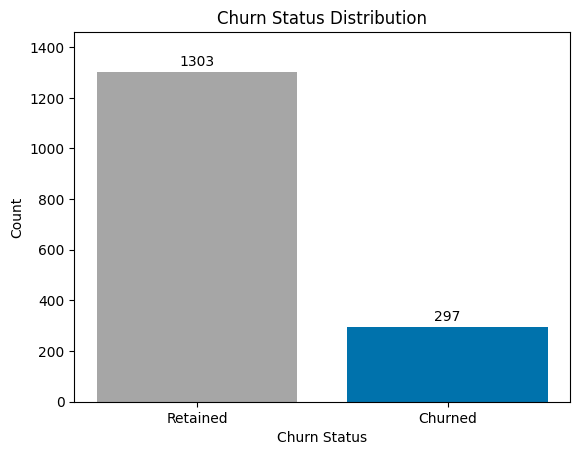

In [ ]:
churn_counts = df["Churn"].value_counts().sort_index()
churn_distribution = plt.bar(churn_counts.index.map(Y_features), churn_counts.values, color = ["#A6A6A6", "#0072AC"])
plt.bar_label(churn_distribution, fmt="%d", padding=2)
plt.xlabel("Churn Status")
plt.ylabel("Count")
plt.title("Churn Status Distribution")
plt.margins(y=0.12)
plt.show()

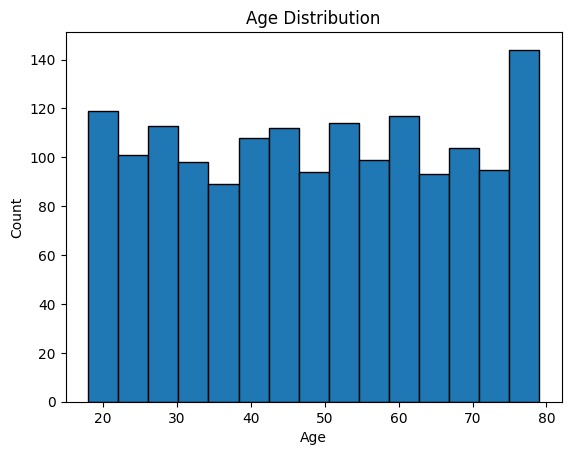

In [ ]:
plt.hist(df["Age"], bins = 15, edgecolor = "black")
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution")
plt.show()

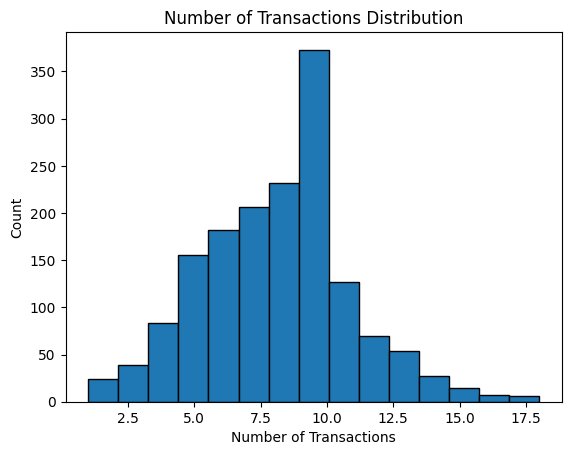

In [ ]:
plt.hist(df["NumTransactions_Last6Months"], bins = 15, edgecolor = "black")
plt.xlabel("Number of Transactions")
plt.ylabel("Count")
plt.title("Number of Transactions Distribution")
plt.show()

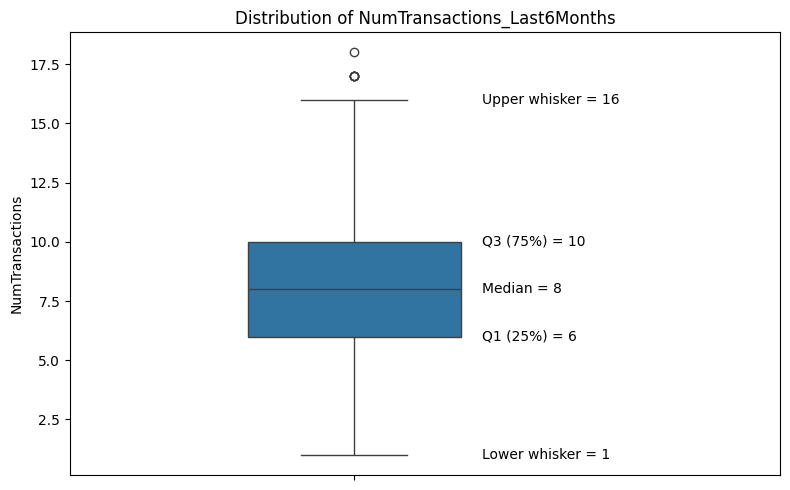

In [ ]:
x = df['NumTransactions_Last6Months'].dropna()
q1 = x.quantile(0.25)
median = x.quantile (0.5)
q3 = x.quantile(0.75)
iqr = q3 - q1

lower_whisker = max (x.min(), q1 - 1.5 * iqr)
upper_whisker = min (x.max(), q3 + 1.5 * iqr)

fig, ax = plt.subplots(figsize = (8,5))
sns.boxplot(y=x, ax = ax, width = 0.3)
x_pos = 0.18

ax.text(x_pos, q1, f"Q1 (25%) = {q1:,.0f}", va="center")
ax.text(x_pos, q3, f"Q3 (75%) = {q3:,.0f}", va="center")
ax.text(x_pos, lower_whisker, f"Lower whisker = {lower_whisker:,.0f}", va="center")
ax.text(x_pos, upper_whisker, f"Upper whisker = {upper_whisker:,.0f}", va="center")
ax.text(x_pos, median, f"Median = {median:,.0f}", va="center")

ax.set_xlim(-0.4, 0.6)
ax.set_title("Distribution of NumTransactions_Last6Months")
ax.set_ylabel("NumTransactions")
plt.tight_layout()

plt.show()

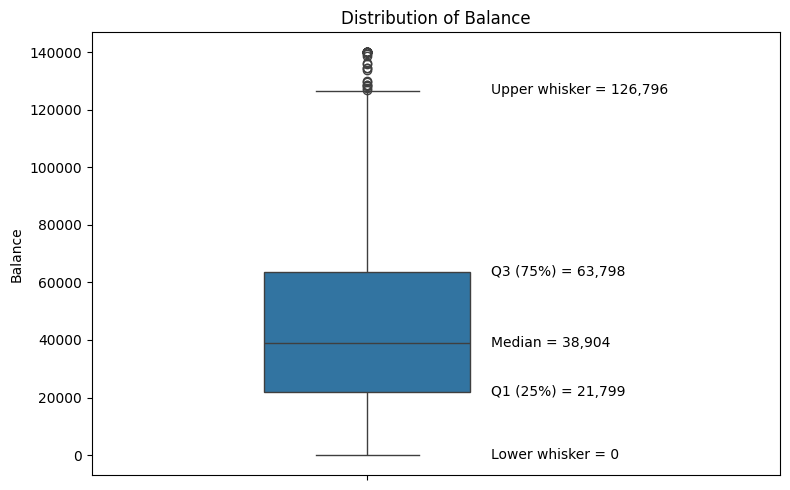

In [ ]:
x = df['Balance'].dropna()
q1 = x.quantile(0.25)
median = x.quantile (0.5)
q3 = x.quantile(0.75)
iqr = q3 - q1

lower_whisker = max (x.min(), q1 - 1.5 * iqr)
upper_whisker = min (x.max(), q3 + 1.5 * iqr)

fig, ax = plt.subplots(figsize = (8,5))
sns.boxplot(y=x, ax = ax, width = 0.3)
x_pos = 0.18

ax.text(x_pos, q1, f"Q1 (25%) = {q1:,.0f}", va="center")
ax.text(x_pos, q3, f"Q3 (75%) = {q3:,.0f}", va="center")
ax.text(x_pos, lower_whisker, f"Lower whisker = {lower_whisker:,.0f}", va="center")
ax.text(x_pos, upper_whisker, f"Upper whisker = {upper_whisker:,.0f}", va="center")
ax.text(x_pos, median, f"Median = {median:,.0f}", va="center")

ax.set_xlim(-0.4, 0.6)
ax.set_title("Distribution of Balance")
ax.set_ylabel("Balance")
plt.tight_layout()

plt.show()

### **4.3. Bivariate Analysis**

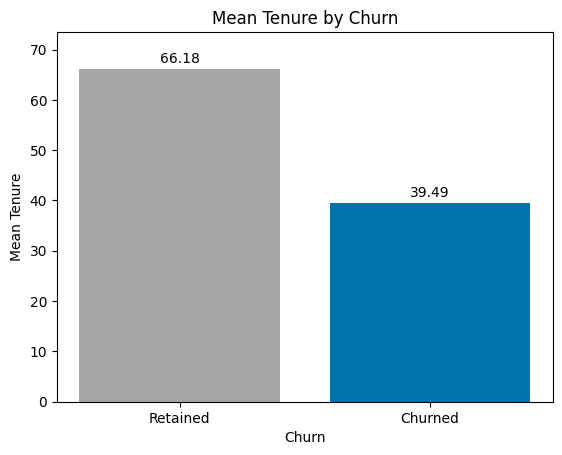

In [ ]:
mean_tenure = df.groupby("Churn")["TenureMonths"].mean()
mean_tenure_bar = plt.bar(mean_tenure.index.map(Y_features), mean_tenure.values, color = ["#A6A6A6", "#0072AC"])
plt.bar_label(mean_tenure_bar,fmt="%.2f", padding=2)
plt.xlabel("Churn")
plt.ylabel("Mean Tenure")
plt.title("Mean Tenure by Churn")
plt.margins(y=0.11)
plt.show()

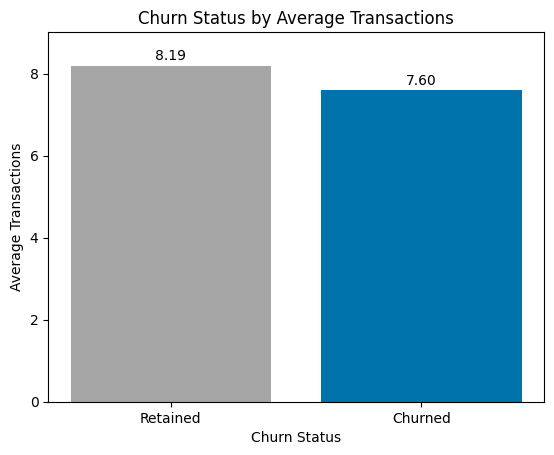

In [ ]:
mean_transactions = df.groupby("Churn")["NumTransactions_Last6Months"].mean()
mean_transactions_bar = plt.bar(mean_transactions.index.map(Y_features), mean_transactions.values, color=["#A6A6A6", "#0072AC"])
plt.bar_label(mean_transactions_bar,fmt="%.2f", padding=2)
plt.xlabel("Churn Status")
plt.ylabel("Average Transactions")
plt.title("Churn Status by Average Transactions")
plt.margins(y=0.10)
plt.show()

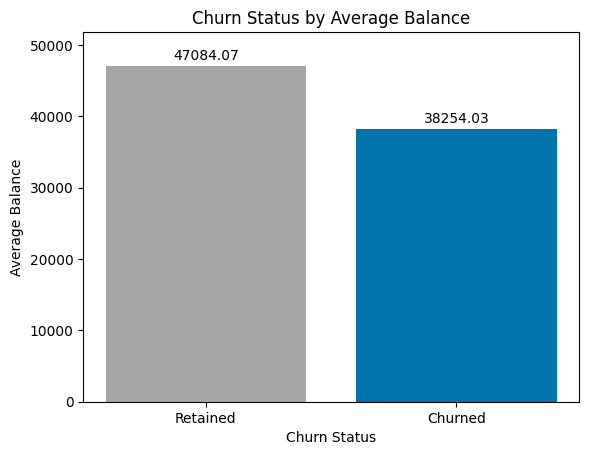

In [ ]:
mean_balance = df.groupby("Churn")["Balance"].mean()
mean_balance_bar = plt.bar(mean_balance.index.map(Y_features), mean_balance.values, color=["#A6A6A6", "#0072AC"])
plt.bar_label(mean_balance_bar,fmt="%.2f", padding=2)
plt.xlabel("Churn Status")
plt.ylabel("Average Balance")
plt.title("Churn Status by Average Balance")
plt.margins(y=0.10)
plt.show()

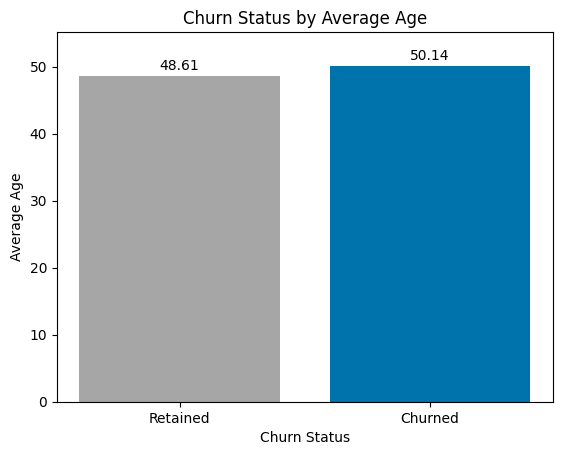

In [ ]:
mean_age = df.groupby("Churn")["Age"].mean()
mean_age_bar = plt.bar(mean_age.index.map(Y_features), mean_age.values, color=["#A6A6A6", "#0072AC"])
plt.bar_label(mean_age_bar,fmt="%.2f", padding=2)
plt.xlabel("Churn Status")
plt.ylabel("Average Age")
plt.title("Churn Status by Average Age")
plt.margins(y=0.10)
plt.show()

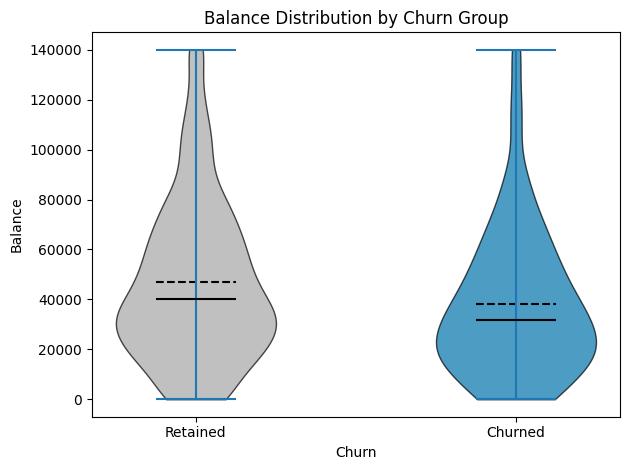

In [ ]:
import matplotlib.pyplot as plt

balance_retain = df.loc[df["Churn"] == 0, "Balance"].dropna()
balance_churn = df.loc[df["Churn"] == 1, "Balance"].dropna()

balance_distribution = plt.violinplot(
    [balance_retain, balance_churn],
    positions=[0, 1],
    showmeans=True,
    showmedians=True
)

# Mean: dashed black line
balance_distribution["cmeans"].set_color("black")
balance_distribution["cmeans"].set_linestyle("--")

# Median: solid black line
balance_distribution["cmedians"].set_color("black")
balance_distribution["cmedians"].set_linestyle("-")

colors = ["#A6A6A6", "#0072AC"]
for body, color in zip(balance_distribution["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.7)


plt.xticks([0, 1], ["Retained", "Churned"])
plt.xlabel("Churn")
plt.ylabel("Balance")
plt.title("Balance Distribution by Churn Group")
plt.tight_layout()
plt.show()

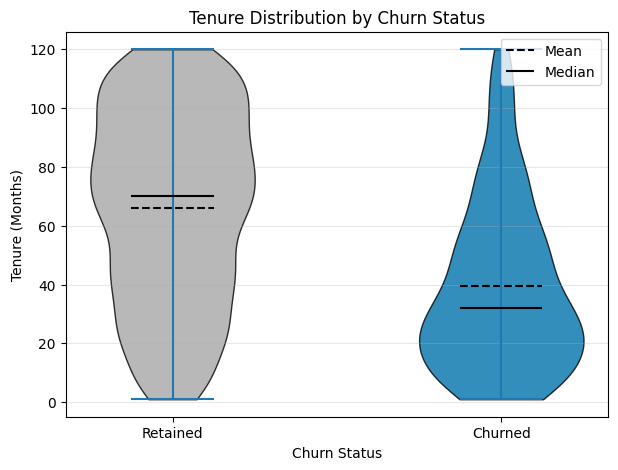

In [ ]:
retained = df.loc[df["Churn"] == 0, "TenureMonths"].dropna()
churned = df.loc[df["Churn"] == 1, "TenureMonths"].dropna()
fig, ax = plt.subplots(figsize=(7, 5))

parts = ax.violinplot(
    [retained, churned],
    positions=[1, 2],
    showmeans=True,
    showmedians=True
)
parts["cmeans"].set_color("black")
parts["cmeans"].set_linestyle("--")  # Mean: dashed

parts["cmedians"].set_color("black")
parts["cmedians"].set_linestyle("-")  # Median: solid
colors = ["#A6A6A6", "#0072AC"]
for body, color in zip(parts["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.8)

ax.set_xticks([1, 2])
ax.set_xticklabels(["Retained", "Churned"])

ax.set_xlabel("Churn Status")
ax.set_ylabel("Tenure (Months)")
ax.set_title("Tenure Distribution by Churn Status")
ax.legend(
    handles=[parts["cmeans"], parts["cmedians"]],
    labels=["Mean", "Median"],
    loc="upper right"
)

ax.grid(axis="y", alpha=0.3)
plt.show()

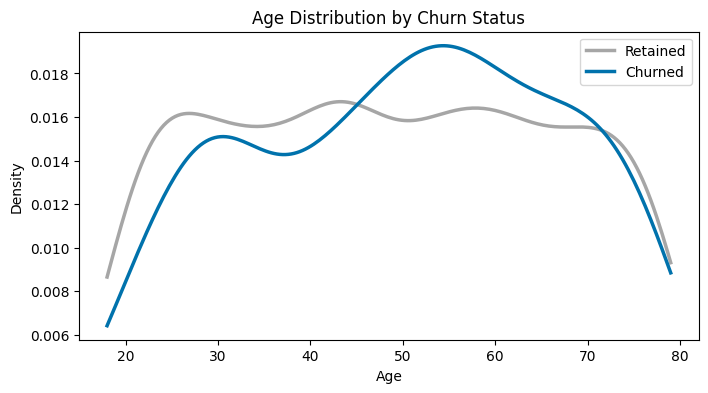

In [ ]:
plt.figure(figsize=(8, 4))
sns.kdeplot(
    data=df[df["Churn"] == 0],
    x="Age",
    label="Retained",
    color = "#A6A6A6",
    linewidth=2.5,
    fill=False,
    bw_adjust=1,
    cut=0
)

sns.kdeplot(
    data=df[df["Churn"] == 1],
    x="Age",
    label="Churned",
    color="#0072AC",
    linewidth=2.5,
    fill=False,
    bw_adjust=1,
    cut=0
)
plt.xlabel("Age")
plt.ylabel("Density")
plt.title("Age Distribution by Churn Status")
plt.legend()
plt.show()

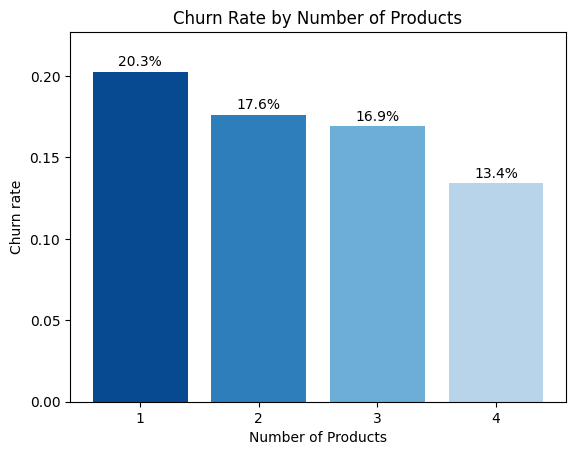

In [ ]:
product_summary = (
    df.groupby("NumProducts")["Churn"]
    .agg(rate="mean", n="size")
    .sort_index()
)

colors = plt.cm.Blues(np.linspace(0.9, 0.3, len(product_summary)))
x = np.arange(len(product_summary))

plt.bar(x, product_summary["rate"], color=colors)
product_bars = plt.bar(x, product_summary["rate"], color=colors)

plt.bar_label(
    product_bars,
    labels=[f"{v:.1%}" for v in product_summary["rate"]],
    padding=2
)
plt.xticks(x, product_summary.index)

plt.margins(y=0.12)
plt.xlabel("Number of Products")
plt.ylabel("Churn rate")
plt.title("Churn Rate by Number of Products")
plt.show()

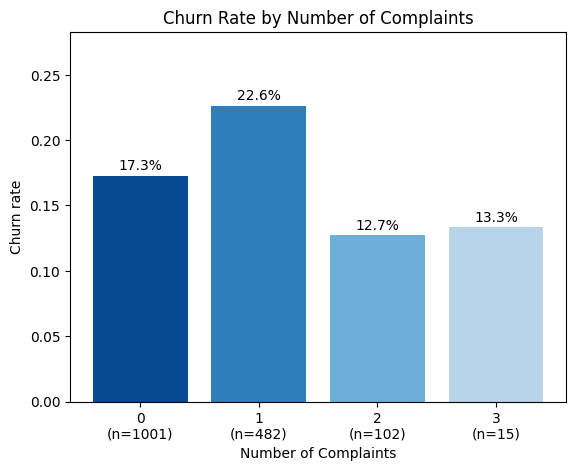

In [ ]:
complaints_summary = (
    df.groupby("ComplaintsLast6Months")["Churn"]
    .agg(rate="mean", n="size")
    .sort_index()
)
colors = plt.cm.Blues(np.linspace(0.9, 0.3, len(complaints_summary)))
complaints_labels = [f"{idx}\n(n={int(n)})" for idx, n in zip(complaints_summary.index, complaints_summary["n"])]
complaints_bars = plt.bar(range(len(complaints_summary)), complaints_summary["rate"], color=colors)
plt.bar_label(complaints_bars, labels=[f"{v:.1%}" for v in complaints_summary["rate"]], padding=2)
plt.xticks(range(len(complaints_summary)), complaints_labels)
plt.ylim(0, complaints_summary["rate"].max() * 1.25)
plt.xlabel("Number of Complaints")
plt.ylabel("Churn rate")
plt.title("Churn Rate by Number of Complaints")
plt.show()


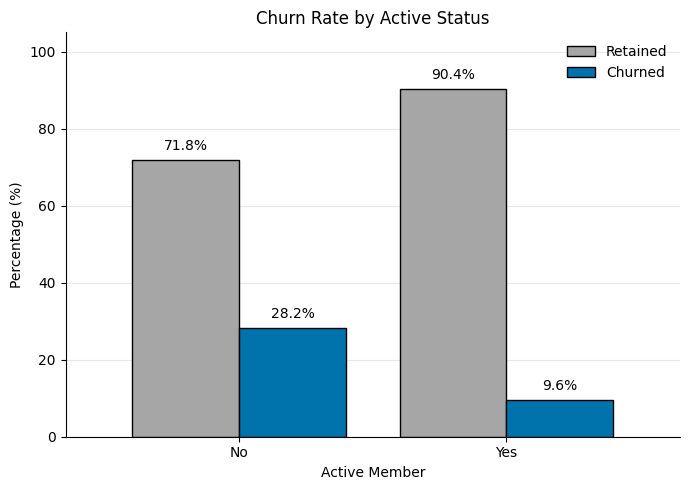

In [ ]:
prop = (
    pd.crosstab(df["IsActiveMember"], df["Churn"], normalize="index") * 100
).round(1)

ax = prop.plot(
    kind="bar",
    stacked=False,
    color=["#A6A6A6", "#0072AC"],
    figsize=(7, 5),
    edgecolor="black",
    width=0.8
)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.1f}%",
            (p.get_x() + p.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10
        )
ax.set_title("Churn Rate by Active Status")
ax.set_xlabel("Active Member")
ax.set_ylabel("Percentage (%)")
ax.set_xticklabels(["No", "Yes"], rotation=0)
ax.set_ylim(0, 105)

ax.legend(["Retained", "Churned"], loc="upper right", frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### **4.3. Multivariate Analysis**

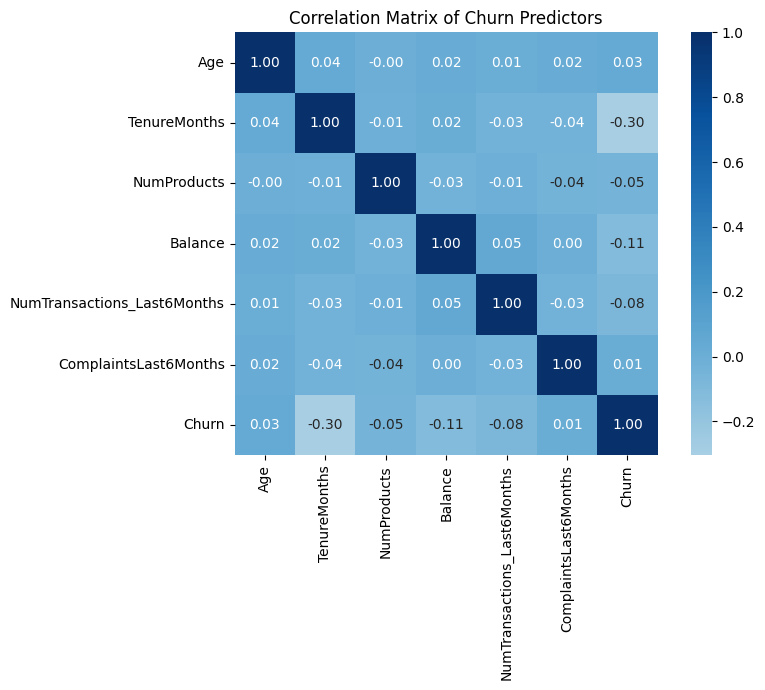

In [ ]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap = 'Blues',
    center=0,
    square=True
)

plt.title("Correlation Matrix of Churn Predictors")
plt.tight_layout()
plt.show()

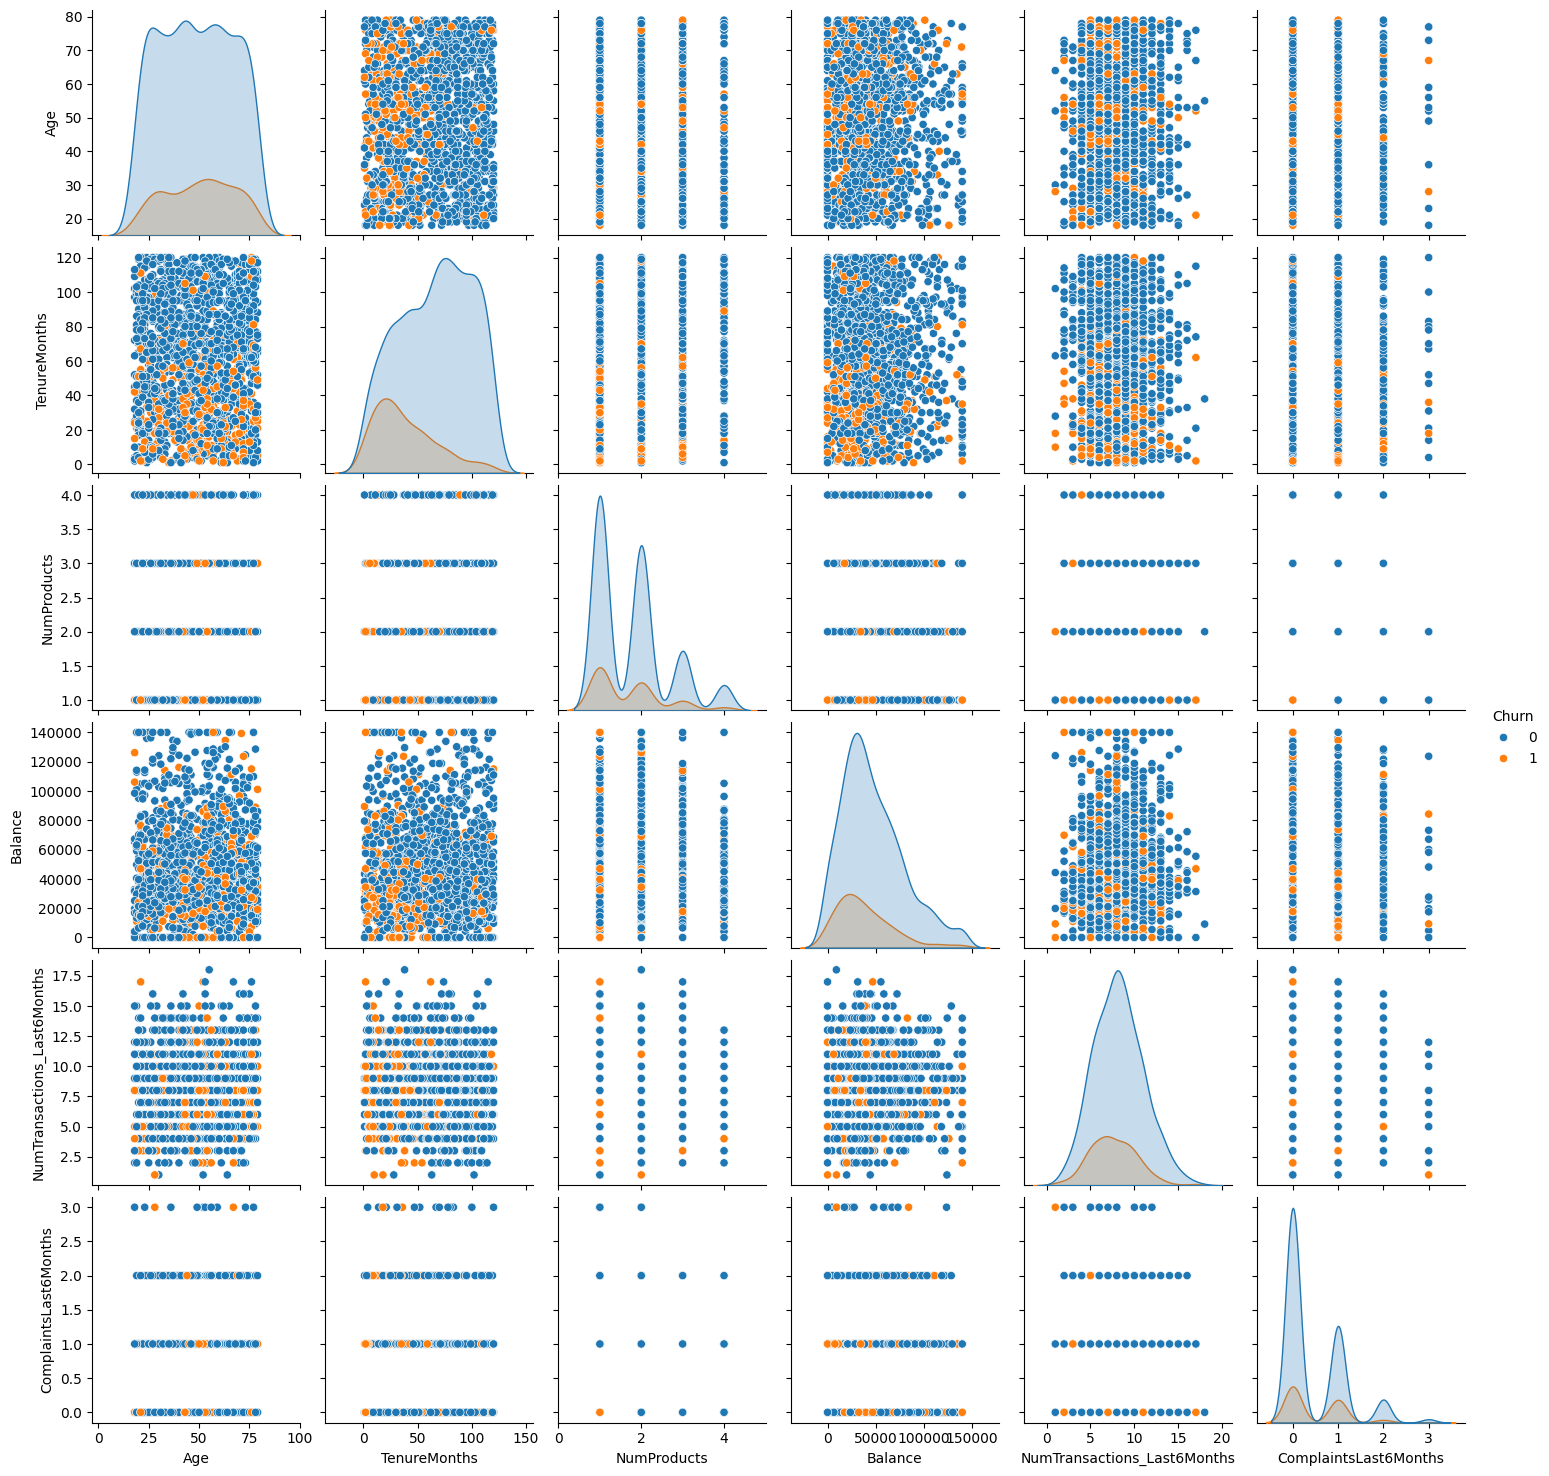

In [ ]:
sns.pairplot(df,hue="Churn")
plt.show()

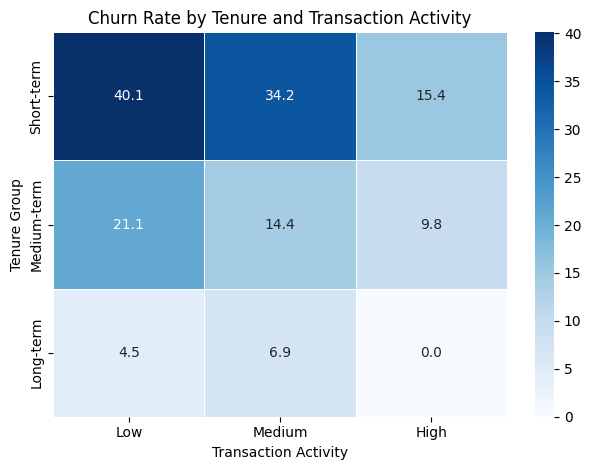

In [ ]:
#Grouping TenureMonths into Short-term, Medium-term, Long-term
df ["TenureGroup"] = pd.cut (
    df ["TenureMonths"],
    bins = [0, 40, 80, 120],
    labels = ["Short-term", "Medium-term", "Long-term"]
)

#Grouping Transactions into Low, Medium, High
df["TransactionGroup"] = pd.cut(
    df["NumTransactions_Last6Months"],
    bins=[0, 6, 12, 18],
    labels=["Low", "Medium", "High"]
)

#Tenure + Transactions --> Churn
churn_tenure_trans = (
    df.groupby(
        [ "TenureGroup", "TransactionGroup"], observed = True
    )['Churn']. mean().mul(100).round(1).reset_index(name ="ChurnRate")
)

heatmap_data = churn_tenure_trans.pivot(
    index = "TenureGroup",
    columns = "TransactionGroup",
    values = "ChurnRate"
)
sns.heatmap(
    heatmap_data,
    annot = True,
    fmt = ".1f",
    cmap = "Blues",
    linewidths= 0.5
)
plt.title('Churn Rate by Tenure and Transaction Activity')
plt.xlabel('Transaction Activity')
plt.ylabel('Tenure Group')

plt.tight_layout()
plt.show()


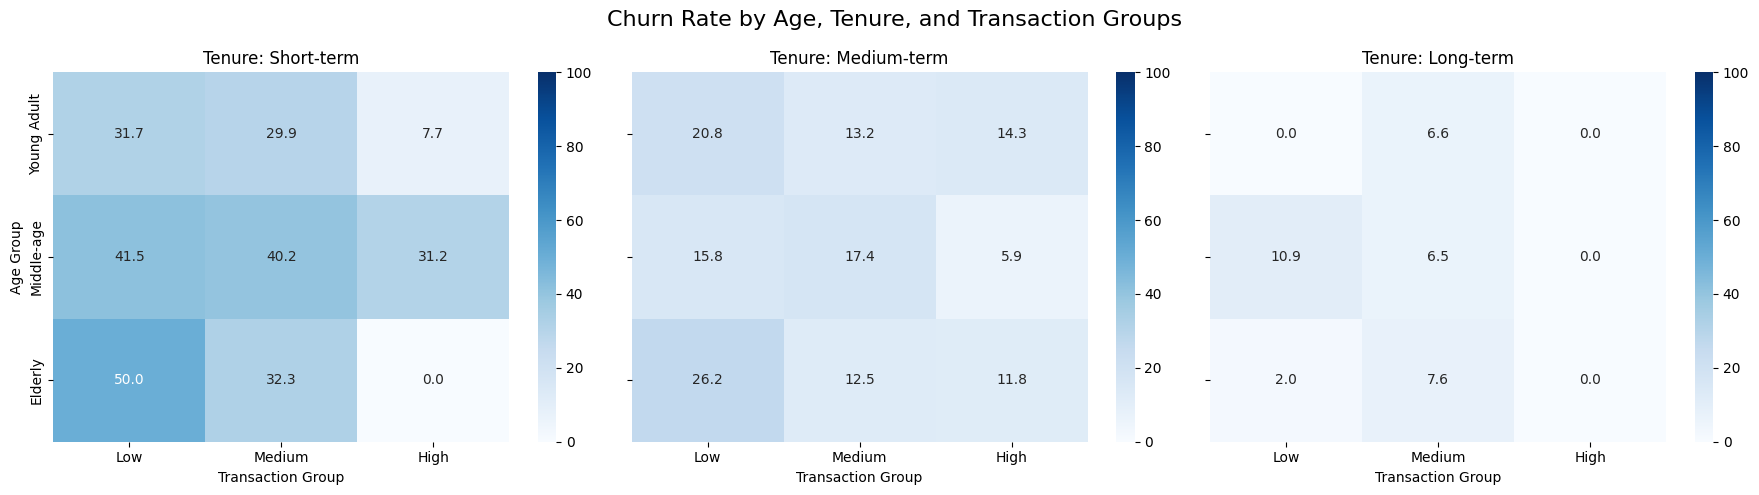

In [ ]:
df ["AgeGroup"] = pd.cut (
    df ["Age"],
    bins = [0,39,59, float ("inf")],
    labels = ["Young Adult", "Middle-age", "Elderly" ]
)

#Age + Tenure + TransactionGroup --> Churn
churn_table = (
    df.groupby(
        ["AgeGroup", "TenureGroup", "TransactionGroup"], observed = True
    )['Churn']. mean().mul(100).round(1).reset_index(name ="ChurnRate")
)

fig, axes = plt.subplots (1,3, figsize =(18,5), sharey = True)
tenure_levels = ["Short-term", "Medium-term", "Long-term"]
for ax, tenure in zip (axes, tenure_levels):
  data = churn_table[churn_table["TenureGroup"] == tenure]
  heatmap_data = data.pivot (
      index = "AgeGroup",
      columns = "TransactionGroup",
      values = "ChurnRate"
  )
  sns.heatmap (
      heatmap_data,
      annot = True,
      fmt = ".1f",
      cmap = "Blues",
      vmin = 0,
      vmax = 100,
      ax = ax
  )
  ax.set_title(f"Tenure: {tenure}")
  ax.set_xlabel("Transaction Group")
  ax.set_ylabel("Age Group" if tenure == "Short-term" else"")

plt.suptitle (
    "Churn Rate by Age, Tenure, and Transaction Groups",
    fontsize = 16
)
plt.tight_layout()
plt.show()

In [ ]:
h1_corr = df["TenureMonths"].corr(df["Churn"])
print(f"H1 correlation between TenureMonths and Churn: {h1_corr:.2f}")
print(df.groupby("TenureGroup", observed=True)["Churn"].mean().mul(100).round(1))

short_term = df[df["TenureGroup"] == "Short-term"]
h2 = short_term.groupby("TransactionGroup", observed=True)["Churn"].agg(["mean", "size"])
h2["mean"] = (h2["mean"] * 100).round(1)
print(h2.rename(columns={"mean": "ChurnRate_%", "size": "Customers"}))

short_low = short_term[short_term["TransactionGroup"] == "Low"]
h3 = short_low.groupby("IsActiveMember")["Churn"].agg(["mean", "size"])
h3["mean"] = (h3["mean"] * 100).round(1)
print(h3.rename(columns={"mean": "ChurnRate_%", "size": "Customers"}))

H1 correlation between TenureMonths and Churn: -0.30
TenureGroup
Short-term     34.6
Medium-term    16.1
Long-term       5.8
Name: Churn, dtype: float64
                  ChurnRate_%  Customers
TransactionGroup                        
Low                      40.1        157
Medium                   34.2        313
High                     15.4         39
                ChurnRate_%  Customers
IsActiveMember                        
No                     59.2         76
Yes                    22.2         81


## **5. Data Preprocessing**

### **5.1. Features and target**

In [ ]:
X = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"]

### **5.2. Train-test split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=RANDOM_STATE,stratify=y)

### **5.3. Preprocessing Pipeline**

In [ ]:
numeric_features = ["Age", "TenureMonths", "NumProducts", "Balance", "NumTransactions_Last6Months"]
categorical_features = ["Gender", "IsActiveMember", "ComplaintsLast6Months"]
category_levels = {
    "Gender": ["Female", "Male"],
    "IsActiveMember": ["No", "Yes"],
    "ComplaintsLast6Months": [0, 1, 2, 3],
}

def build_preprocessor(scale_numeric=True, cat_features=None, num_features=None):
    if num_features is None:
        num_features = numeric_features
    if cat_features is None:
        cat_features = categorical_features
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    transformers = []
    if len(num_features) > 0:
        transformers.append(("num", numeric_step, list(num_features)))
    if len(cat_features) > 0:
        transformers.append((
            "cat",
            OneHotEncoder(
                categories=[category_levels[col] for col in cat_features],
                drop="first",
                sparse_output=False,
            ),
            list(cat_features),
        ))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

### **5.4. Cross-validation**

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### **5.5. Evaluation Method**

In [ ]:
def precision_at_10_percent(y_true, y_proba):
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)
    if y_proba.ndim == 2:
        y_proba = y_proba[:, 1]
    num_contact = int(np.ceil(len(y_true) * 0.10))
    top = np.argsort(-y_proba)[:num_contact]
    return y_true[top].mean()

def out_of_fold_ranking(pipeline):
    probabilities = cross_val_predict(pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    return precision_at_10_percent(y_train, probabilities), roc_auc_score(y_train, probabilities)

### **5.6. Feature tests**

In [ ]:
feature_tests = []
for column in ["Age", "TenureMonths", "Balance", "NumTransactions_Last6Months"]:
    churned = X_train.loc[y_train == 1, column]
    retained = X_train.loc[y_train == 0, column]
    statistic, p_value = ttest_ind(churned, retained, equal_var=False)
    feature_tests.append({"Feature": column, "Test": "Welch t-test", "Statistic": statistic, "p-value": p_value})

for column in ["NumProducts", "Gender", "IsActiveMember", "ComplaintsLast6Months"]:
    table = pd.crosstab(X_train[column], y_train)
    statistic, p_value, dof, expected = chi2_contingency(table)
    feature_tests.append({"Feature": column, "Test": "Chi-square", "Statistic": statistic, "p-value": p_value})

univariate_tests = pd.DataFrame(feature_tests).sort_values("p-value")

def fold_precision(scale_numeric, num_features, cat_features, model):
    candidate = Pipeline([
        ("preprocess", build_preprocessor(
            scale_numeric=scale_numeric,
            num_features=num_features,
            cat_features=cat_features,
        )),
        ("model", model),
    ])
    fold_scores = []
    probabilities = np.zeros(len(X_train))
    for train_index, test_index in cv.split(X_train, y_train):
        candidate.fit(X_train.iloc[train_index], y_train.iloc[train_index])
        fold_probabilities = candidate.predict_proba(X_train.iloc[test_index])[:, 1]
        probabilities[test_index] = fold_probabilities
        fold_scores.append(precision_at_10_percent(y_train.iloc[test_index], fold_probabilities))
    return np.asarray(fold_scores), precision_at_10_percent(y_train, probabilities)

def select_features(scale_numeric, make_model, model_name):
    full_scores, full_precision = fold_precision(scale_numeric, numeric_features, categorical_features, make_model())
    rows = []
    for feature in numeric_features + categorical_features:
        kept_numeric = [column for column in numeric_features if column != feature]
        kept_categorical = [column for column in categorical_features if column != feature]
        reduced_scores, reduced_precision = fold_precision(scale_numeric, kept_numeric, kept_categorical, make_model())
        differences = np.asarray(full_scores) - np.asarray(reduced_scores)
        if np.allclose(differences, 0):
            statistic, p_value_feature = 0.0, 1.0
        else:
            paired = ttest_rel(full_scores, reduced_scores, alternative="greater")
            statistic, p_value_feature = float(paired.statistic), float(paired.pvalue)
        association = univariate_tests.set_index("Feature").loc[feature]
        rows.append({
            "Feature": feature,
            "Test": association["Test"],
            "Statistic": association["Statistic"],
            "Association p-value": float(association["p-value"]),
            "Precision with feature": full_precision,
            "Precision without feature": reduced_precision,
            "Gain": full_precision - reduced_precision,
            "t": statistic,
            "Model p-value": p_value_feature,
        })
    tests = pd.DataFrame(rows).sort_values(["Model p-value", "Feature"])
    tests["Keep"] = (tests["Association p-value"] < 0.05) | (tests["Model p-value"] < 0.05)
    print(f"{model_name}: association test and this model's paired test. Keep a feature if either p-value is below 0.05.")
    print(tests.to_string(
        index=False,
        formatters={
            "Statistic": "{:.3f}".format,
            "Association p-value": "{:.4g}".format,
            "Precision with feature": "{:.3f}".format,
            "Precision without feature": "{:.3f}".format,
            "Gain": "{:.3f}".format,
            "t": "{:.2f}".format,
            "Model p-value": "{:.4f}".format,
        },
    ))
    kept = set(tests.loc[tests["Keep"], "Feature"])
    if not kept:
        best_feature = tests.iloc[0]["Feature"]
        kept = {best_feature}
        print(f"{model_name} had no feature below 0.05. Keeping {best_feature}.")
    selected_numeric = [column for column in numeric_features if column in kept]
    selected_categorical = [column for column in categorical_features if column in kept]
    print(f"{model_name} keeps:", selected_numeric + selected_categorical)
    return selected_numeric, selected_categorical

## **6. Modelling**

### **6.1. Baseline Model**

In [ ]:
majority_class = y_train.mode()[0]

In [ ]:
print(classification_report(y_train, np.full(len(y_train), majority_class), zero_division=0))

              precision    recall  f1-score   support

           0       0.81      1.00      0.90      1042
           1       0.00      0.00      0.00       238

    accuracy                           0.81      1280
   macro avg       0.41      0.50      0.45      1280
weighted avg       0.66      0.81      0.73      1280



### **6.2. Other Models**

#### **6.2.1. Logistic Regression**

In [ ]:
logistic_numeric, logistic_categorical = select_features(
    True,
    lambda: LogisticRegression(C=1, class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000),
    "Logistic regression",
)

Logistic regression: association test and this model's paired test. Keep a feature if either p-value is below 0.05.
                    Feature         Test Statistic Association p-value Precision with feature Precision without feature   Gain     t Model p-value  Keep
               TenureMonths Welch t-test   -13.031           1.352e-32                  0.586                     0.359  0.227 10.59        0.0002  True
             IsActiveMember   Chi-square    68.429           1.315e-16                  0.586                     0.461  0.125  2.81        0.0241  True
      ComplaintsLast6Months   Chi-square     6.813              0.0781                  0.586                     0.555  0.031 -0.00        0.5000 False
NumTransactions_Last6Months Welch t-test    -3.481           0.0005584                  0.586                     0.594 -0.008 -0.25        0.5925  True
                    Balance Welch t-test    -4.210           3.196e-05                  0.586                     0.578

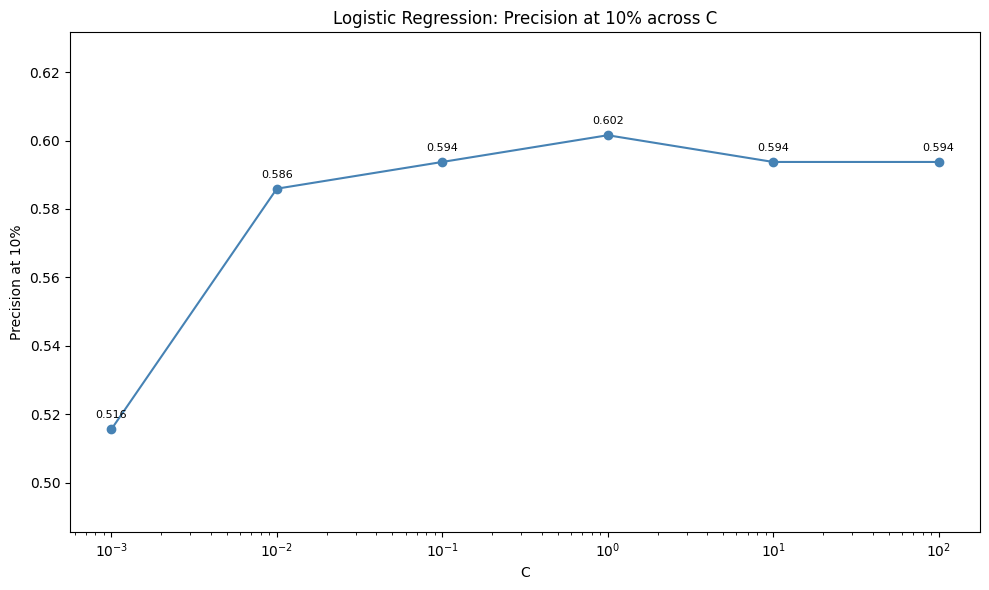

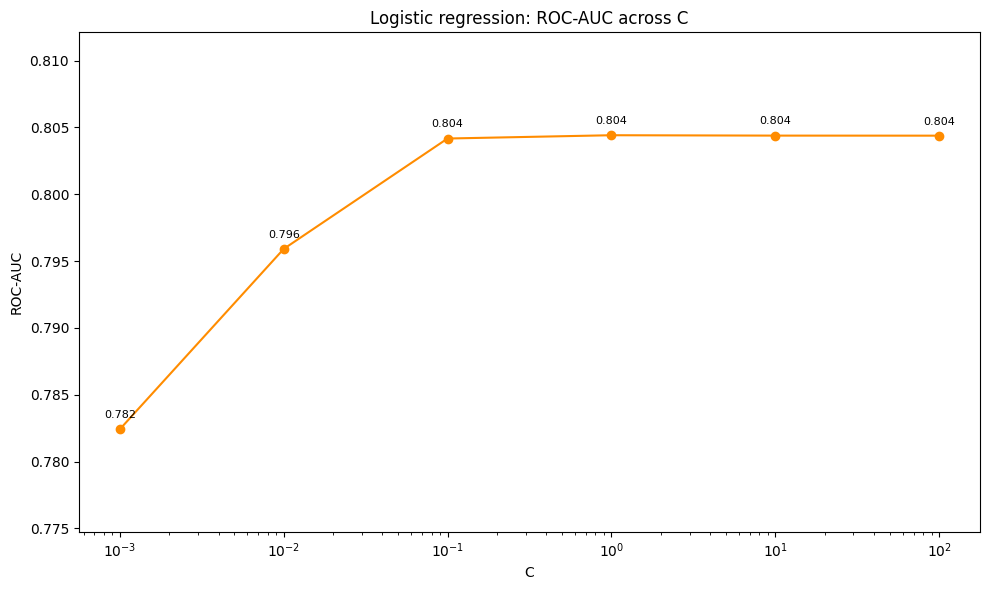

In [ ]:
C_grid = [0.001, 0.01, 0.1, 1, 10, 100]
log_cv_precision_10 = []
log_cv_roc_auc = []

for C in C_grid:
    candidate = Pipeline([
        ("preprocess", build_preprocessor(scale_numeric=True, num_features=logistic_numeric, cat_features=logistic_categorical)),
        ("model", LogisticRegression(C=C, class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000)),
    ])
    precision_at_10, roc_auc = out_of_fold_ranking(candidate)
    log_cv_precision_10.append(precision_at_10)
    log_cv_roc_auc.append(roc_auc)

best_C = C_grid[int(np.argmax(log_cv_precision_10))]

plt.figure(figsize=(10, 6))
plt.semilogx(C_grid, log_cv_precision_10, "o-", color="steelblue")
for C, score in zip(C_grid, log_cv_precision_10):
    plt.annotate(f"{score:.3f}", (C, score), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("C")
plt.ylabel("Precision at 10%")
plt.title("Logistic Regression: Precision at 10% across C")
plt.margins(y=0.35)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.semilogx(C_grid, log_cv_roc_auc, "o-", color="darkorange")
for C, score in zip(C_grid, log_cv_roc_auc):
    plt.annotate(f"{score:.3f}", (C, score), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("C")
plt.ylabel("ROC-AUC")
plt.title("Logistic regression: ROC-AUC across C")
plt.margins(y=0.35)
plt.tight_layout()
plt.show()

logistic_regression = Pipeline([
    ("preprocess", build_preprocessor(scale_numeric=True, num_features=logistic_numeric, cat_features=logistic_categorical)),
    ("model", LogisticRegression(C=best_C, class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000)),
])

In [ ]:
oof_probabilities = cross_val_predict(
    logistic_regression, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]
logistic_cv_customers = pd.DataFrame({
    "CustomerID": df.loc[X_train.index, "CustomerID"].to_numpy(),
    "ChurnProbability": oof_probabilities,
     "Actual": y_train.map(Y_features).to_numpy()
})
num_contact = int(np.ceil(len(logistic_cv_customers) * 0.10))
logistic_cv_customers = (
    logistic_cv_customers.nlargest(num_contact, "ChurnProbability")
    .reset_index(drop=True)
)
logistic_cv_customers


,CustomerID,ChurnProbability,Actual
0,C51488,0.956022,Churned
1,C37990,0.919668,Churned
2,C44377,0.918026,Churned
3,C36451,0.916216,Churned
4,C27284,0.915083,Churned
...,...,...,...
123,C13582,0.786087,Retained
124,C50922,0.785474,Churned
125,C60370,0.785028,Retained
126,C17678,0.784701,Churned


#### **6.2.2. Decision Tree**

In [ ]:
tree_numeric, tree_categorical = select_features(
    False,
    lambda: DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision tree",
)

Decision tree: association test and this model's paired test. Keep a feature if either p-value is below 0.05.
                    Feature         Test Statistic Association p-value Precision with feature Precision without feature   Gain     t Model p-value  Keep
             IsActiveMember   Chi-square    68.429           1.315e-16                  0.570                     0.367  0.203 10.95        0.0002  True
               TenureMonths Welch t-test   -13.031           1.352e-32                  0.570                     0.281  0.289  9.44        0.0004  True
                    Balance Welch t-test    -4.210           3.196e-05                  0.570                     0.555  0.016  0.00        0.5000  True
                        Age Welch t-test     0.688              0.4917                  0.570                     0.578 -0.008 -1.50        0.8960 False
      ComplaintsLast6Months   Chi-square     6.813              0.0781                  0.570                     0.547  0.02

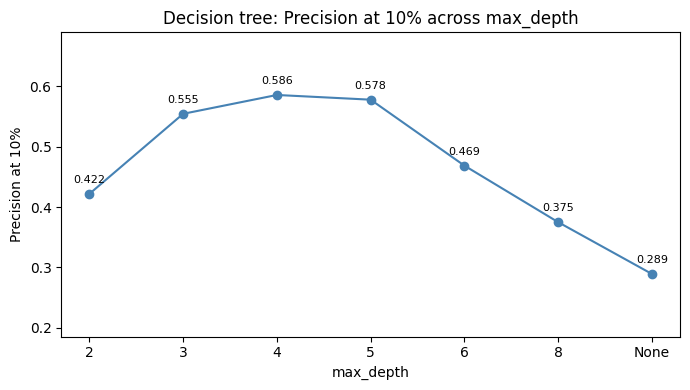

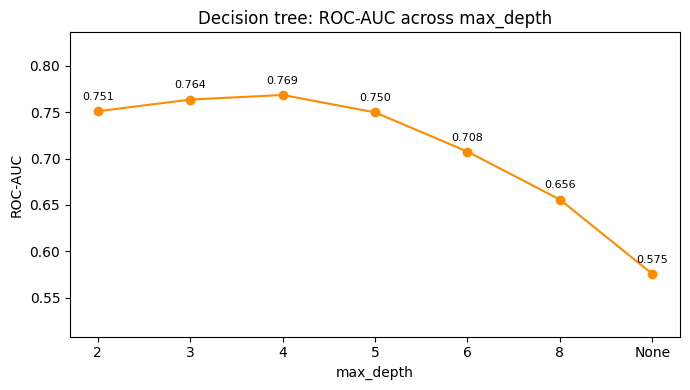

In [ ]:

depths = [2, 3, 4, 5, 6, 8, None]
cv_precision_at_10_tree = []
cv_roc_auc_tree = []

for d in depths:
    candidate = Pipeline([
        ("preprocess", build_preprocessor(scale_numeric=False, num_features=tree_numeric, cat_features=tree_categorical)),
        ("model", DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE)),
    ])
    precision_at_10, roc_auc = out_of_fold_ranking(candidate)
    cv_precision_at_10_tree.append(precision_at_10)
    cv_roc_auc_tree.append(roc_auc)

best_depth = depths[int(np.argmax(cv_precision_at_10_tree))]
depth_labels = [str(d) for d in depths]

plt.figure(figsize=(7, 4))
plt.plot(depth_labels, cv_precision_at_10_tree, "o-", color="steelblue")
for label, score in zip(depth_labels, cv_precision_at_10_tree):
    plt.annotate(f"{score:.3f}", (label, score), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("max_depth")
plt.ylabel("Precision at 10%")
plt.title("Decision tree: Precision at 10% across max_depth")
plt.margins(y=0.35)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(depth_labels, cv_roc_auc_tree, "o-", color="darkorange")
for label, score in zip(depth_labels, cv_roc_auc_tree):
    plt.annotate(f"{score:.3f}", (label, score), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("max_depth")
plt.ylabel("ROC-AUC")
plt.title("Decision tree: ROC-AUC across max_depth")
plt.margins(y=0.35)
plt.tight_layout()
plt.show()
tree = Pipeline([
    ("preprocess", build_preprocessor(scale_numeric=False, num_features=tree_numeric, cat_features=tree_categorical)),
    ("model", DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42)),
])


In [ ]:
tree_oof_probabilities = cross_val_predict(tree, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
tree_oof_pred = cross_val_predict(tree, X_train, y_train, cv=cv)
num_contact = int(np.ceil(len(y_train) * 0.10))
tree_cv_customers = pd.DataFrame({
    "CustomerID": df.loc[X_train.index, "CustomerID"].to_numpy(),
    "ChurnProbability": tree_oof_probabilities,
    "Actual": y_train.map(Y_features).to_numpy()
})
tree_cv_customers = (
    tree_cv_customers.nlargest(num_contact, "ChurnProbability")
    .reset_index(drop=True)
)
tree_cv_customers

,CustomerID,ChurnProbability,Actual
0,C11386,1.000000,Retained
1,C25418,0.880172,Churned
2,C27782,0.880172,Retained
3,C31853,0.880172,Retained
4,C56792,0.880172,Retained
...,...,...,...
123,C48041,0.872255,Retained
124,C56119,0.872255,Churned
125,C46280,0.872255,Churned
126,C29225,0.872255,Retained


#### **6.2.3. K-Nearest Neighbor**

In [ ]:
knn_numeric, knn_categorical = select_features(
    True,
    lambda: KNeighborsClassifier(n_neighbors=25),
    "KNN",
)

KNN: association test and this model's paired test. Keep a feature if either p-value is below 0.05.
                    Feature         Test Statistic Association p-value Precision with feature Precision without feature  Gain    t Model p-value  Keep
             IsActiveMember   Chi-square    68.429           1.315e-16                  0.578                     0.430 0.148 7.76        0.0007  True
               TenureMonths Welch t-test   -13.031           1.352e-32                  0.578                     0.344 0.234 4.16        0.0070  True
                        Age Welch t-test     0.688              0.4917                  0.578                     0.508 0.070 2.71        0.0267  True
                    Balance Welch t-test    -4.210           3.196e-05                  0.578                     0.508 0.070 2.45        0.0352  True
                     Gender   Chi-square     0.553              0.4572                  0.578                     0.523 0.055 2.11        0.0514 

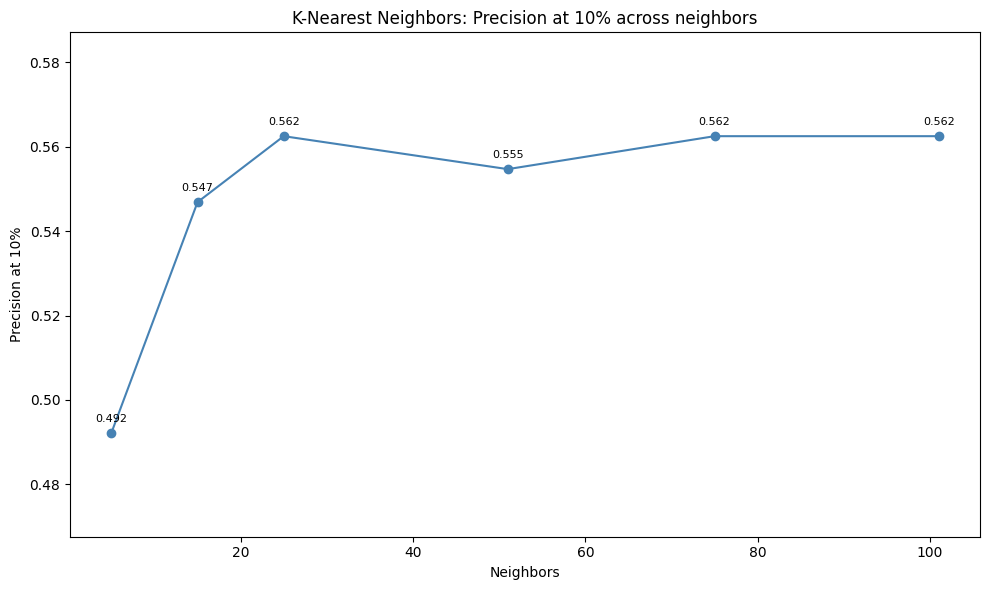

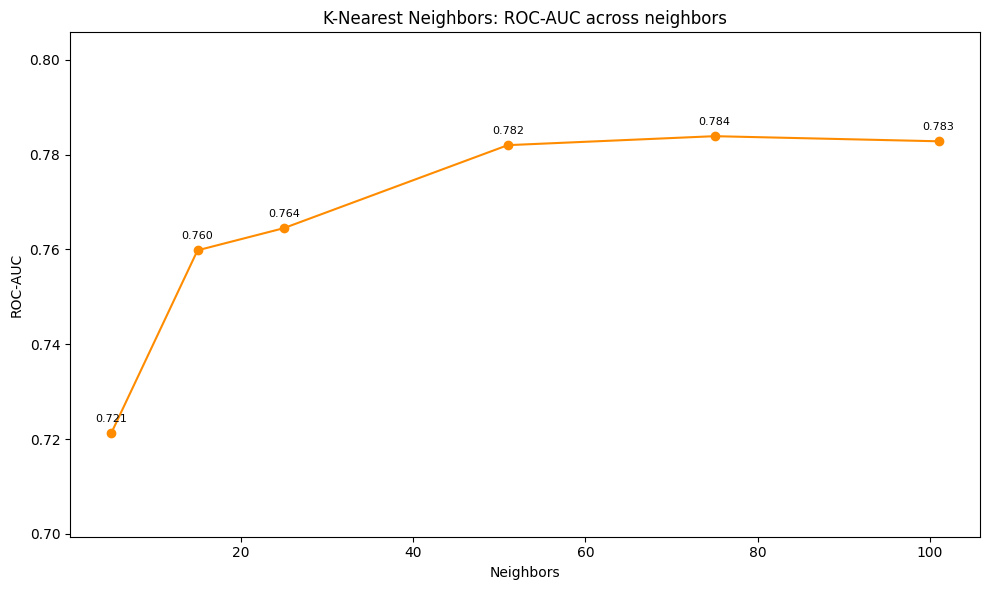

In [ ]:
k_values = [5, 15, 25, 51, 75, 101]
knn_cv_precision_10 = []
knn_cv_roc_auc = []

for k in k_values:
    candidate = Pipeline([
        ("preprocess", build_preprocessor(scale_numeric=True, num_features=knn_numeric, cat_features=knn_categorical)),
        ("model", KNeighborsClassifier(n_neighbors=k)),
    ])
    precision_at_10, roc_auc = out_of_fold_ranking(candidate)
    knn_cv_precision_10.append(precision_at_10)
    knn_cv_roc_auc.append(roc_auc)

best_k = k_values[int(np.argmax(knn_cv_precision_10))]

plt.figure(figsize=(10, 6))
plt.plot(k_values, knn_cv_precision_10, "o-", color="steelblue")
for label, score in zip(k_values, knn_cv_precision_10):
    plt.annotate(f"{score:.3f}", (label, score), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("Neighbors")
plt.ylabel("Precision at 10%")
plt.title("K-Nearest Neighbors: Precision at 10% across neighbors")
plt.margins(y=0.35)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(k_values, knn_cv_roc_auc, "o-", color="darkorange")
for label, score in zip(k_values, knn_cv_roc_auc):
    plt.annotate(f"{score:.3f}", (label, score), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("Neighbors")
plt.ylabel("ROC-AUC")
plt.title("K-Nearest Neighbors: ROC-AUC across neighbors")
plt.margins(y=0.35)
plt.tight_layout()
plt.show()
knn = Pipeline([
    ("preprocess", build_preprocessor(scale_numeric=True, num_features=knn_numeric, cat_features=knn_categorical)),
    ("model", KNeighborsClassifier(n_neighbors=best_k)),
])


In [ ]:
knn_oof_probabilities = cross_val_predict(knn, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
knn_oof_pred = cross_val_predict(knn, X_train, y_train, cv=cv)
num_contact = int(np.ceil(len(y_train) * 0.10))
knn_cv_customers = pd.DataFrame({
    "CustomerID": df.loc[X_train.index, "CustomerID"].to_numpy(),
    "ChurnProbability": knn_oof_probabilities,
    "Actual": y_train.map(Y_features).to_numpy(),
})
knn_cv_customers = (
    knn_cv_customers.nlargest(num_contact, "ChurnProbability")
    .reset_index(drop=True)
)
knn_cv_customers


,CustomerID,ChurnProbability,Actual
0,C51823,0.80,Retained
1,C68990,0.72,Retained
2,C17045,0.72,Churned
3,C18023,0.72,Churned
4,C53738,0.72,Churned
...,...,...,...
123,C28811,0.48,Churned
124,C26421,0.48,Retained
125,C10445,0.48,Retained
126,C58278,0.48,Churned


## **7. Model Evaluation**

### **7.1. Model Selection:**

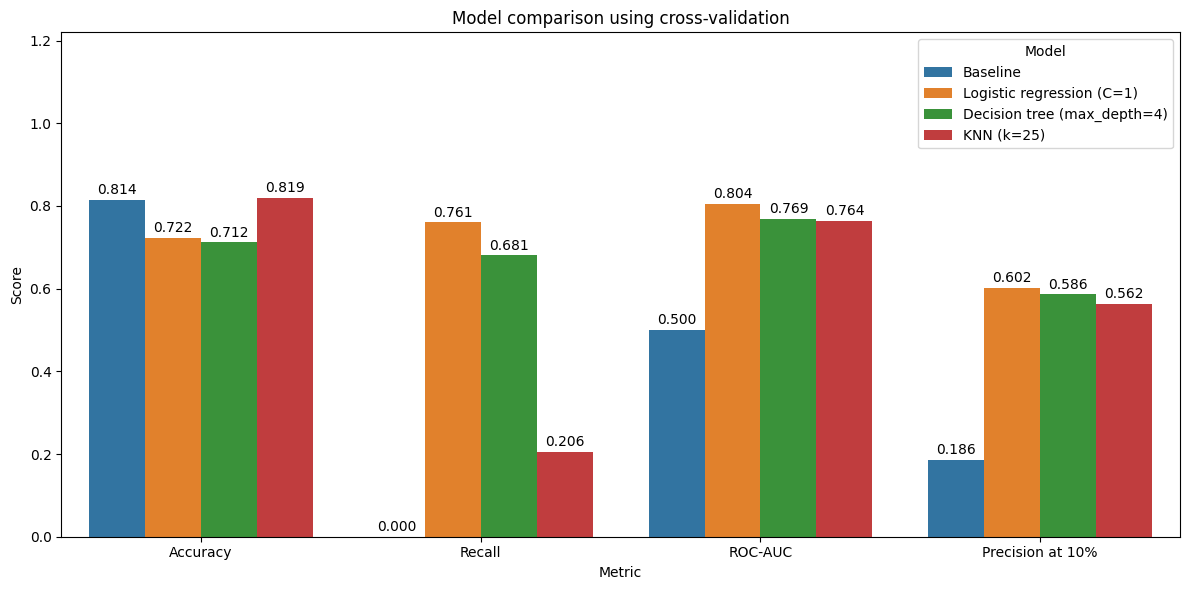

In [ ]:
def training_scores(y_true, y_pred, precision_at_10, roc_auc):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc,
        "precision_at_10": precision_at_10,
    }

y_pred_baseline_train = np.full(len(y_train), majority_class)
baseline_scores = {
    "accuracy": accuracy_score(y_train, y_pred_baseline_train),
    "recall": recall_score(y_train, y_pred_baseline_train, zero_division=0),
    "roc_auc": 0.5,
    "precision_at_10": float(y_train.mean()),
}

oof_pred = (oof_probabilities >= 0.5).astype(int)
logistic_name = f"Logistic regression (C={best_C})"
tree_name = f"Decision tree (max_depth={best_depth})"
knn_name = f"KNN (k={best_k})"

comparison = pd.DataFrame({
    "Baseline": baseline_scores,
    logistic_name: training_scores(
        y_train,
        oof_pred,
        log_cv_precision_10[C_grid.index(best_C)],
        log_cv_roc_auc[C_grid.index(best_C)],
    ),
    tree_name: training_scores(
        y_train,
        tree_oof_pred,
        cv_precision_at_10_tree[depths.index(best_depth)],
        cv_roc_auc_tree[depths.index(best_depth)],
    ),
    knn_name: training_scores(
        y_train,
        knn_oof_pred,
        knn_cv_precision_10[k_values.index(best_k)],
        knn_cv_roc_auc[k_values.index(best_k)],
    ),
})

plot_df = comparison.T.reset_index().rename(columns={"index": "Model"})
plot_df = plot_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
plot_df["Metric"] = plot_df["Metric"].map({
    "accuracy": "Accuracy",
    "recall": "Recall",
    "roc_auc": "ROC-AUC",
    "precision_at_10": "Precision at 10%",
})
model_order = ["Baseline", logistic_name, tree_name, knn_name]
metric_order = ["Accuracy", "Recall", "ROC-AUC", "Precision at 10%"]

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", hue_order=model_order, order=metric_order)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=10, padding=2)
plt.ylim(0, 1.22)
plt.ylabel("Score")
plt.title("Model comparison using cross-validation")
plt.legend(title="Model")
plt.tight_layout()
plt.show()


### **7.2. Model Evaluation**

In [ ]:
logistic_regression.fit(X_train,y_train)
test_probabilities = logistic_regression.predict_proba(X_test)[:, 1]
y_pred_test = (test_probabilities >= 0.5).astype(int)

print("Logistic regression — evaluation on the test set")
print(classification_report(y_test, y_pred_test, zero_division=0))
print(f"roc_auc: {roc_auc_score(y_test, test_probabilities):.3f}")

ranking = pd.DataFrame({
    "ChurnProbability": test_probabilities,
    "ActualChurn": y_test.to_numpy(),
}, index=X_test.index)
num_contact = int(np.ceil(len(ranking) * 0.10))
top_10_percent = ranking.nlargest(num_contact, "ChurnProbability")
test_precision_at_10 = top_10_percent["ActualChurn"].mean()

print(f"Customers in top 10%: {num_contact}")
print(f"Precision at 10%: {test_precision_at_10:.2f}")

Logistic regression — evaluation on the test set
              precision    recall  f1-score   support

           0       0.91      0.72      0.80       261
           1       0.35      0.68      0.46        59

    accuracy                           0.71       320
   macro avg       0.63      0.70      0.63       320
weighted avg       0.81      0.71      0.74       320

roc_auc: 0.782
Customers in top 10%: 32
Precision at 10%: 0.59


## **8. Model Interpretation and Recommendation**

### **8.1. Feature Importance**

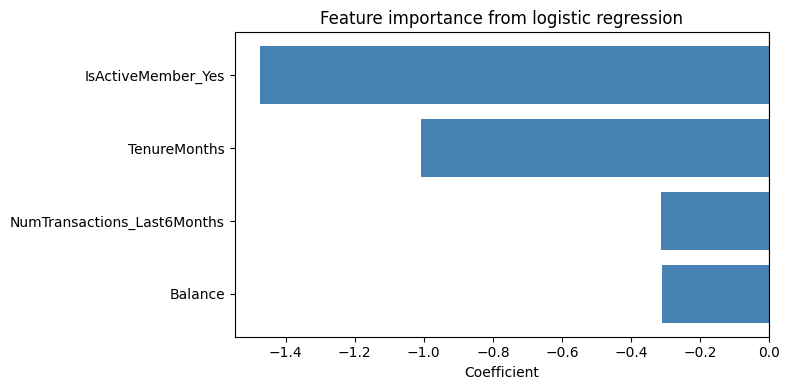

In [ ]:
fitted_logistic = logistic_regression.named_steps["model"]
feature_names = logistic_regression.named_steps["preprocess"].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": fitted_logistic.coef_[0],
})
feature_importance["AbsCoefficient"] = feature_importance["Coefficient"].abs()
feature_importance = feature_importance.sort_values("AbsCoefficient", ascending=False)
plt.figure(figsize=(8, 4))
plot_data = feature_importance.iloc[::-1]
bar_colors = np.where(plot_data["Coefficient"] > 0, "darkorange", "steelblue")
plt.barh(plot_data["Feature"], plot_data["Coefficient"], color=bar_colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient")
plt.title("Feature importance from logistic regression")
plt.tight_layout()
plt.show()

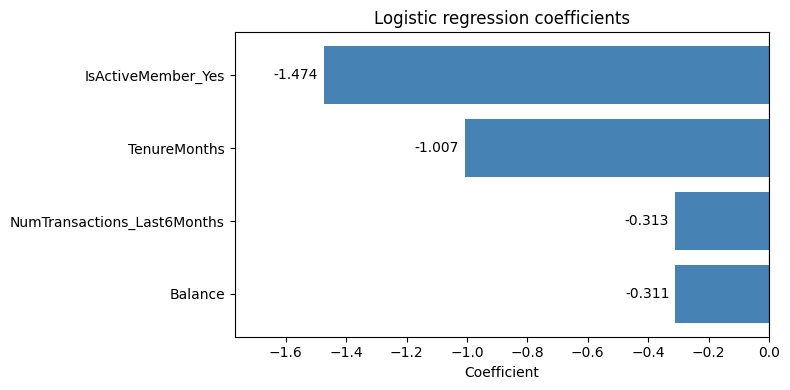

In [ ]:
plt.figure(figsize=(8, 4))
plot_data = feature_importance.iloc[::-1]

bar_colors = np.where(
    plot_data["Coefficient"] > 0, "darkorange", "steelblue"
)

bars = plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"],
    color=bar_colors
)

# Display coefficient values
plt.bar_label(bars, fmt="%.3f", padding=4)
plt.margins(x=0.2)  # Leave space for labels

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient")
plt.title("Logistic regression coefficients")
plt.tight_layout()
plt.show()

### **8.2. Customers to Contact (Top 10%)**

In [ ]:

# checking how good our model is at picking the top 10 percent using the test set only
# the model was trained on the training set so the test set shows how it does on new customers


test_ranking = pd.DataFrame({
    "ChurnProbability": test_probabilities,   # the logistic regression scores from section 7.1
    "ActualChurn": y_test.to_numpy(),
}, index=X_test.index)

num_test_contact = int(np.ceil(len(test_ranking) * 0.10))   # 10 percent of 320 test customers is 32
test_top = test_ranking.nlargest(num_test_contact, "ChurnProbability")   # the 32 highest risk test customers

test_precision = test_top["ActualChurn"].mean()   # how many of the 32 actually churned
base_rate = y_test.mean()   # churn rate if we just picked at random

print(f"Test customers in top 10%: {num_test_contact}")
print(f"Real churners among them: {test_top['ActualChurn'].sum()}")
print(f"Precision at top 10% on test set: {test_precision:.2f}")
print(f"Churn rate in test set: {base_rate:.2f}")
print(f"The model is {test_precision / base_rate:.1f} times better than picking at random")

Test customers in top 10%: 32
Real churners among them: 19
Precision at top 10% on test set: 0.59
Churn rate in test set: 0.18
The model is 3.2 times better than picking at random


In [ ]:
# using the final model to score every customer so the bank knows who to contact
# this is just making the list, not checking accuracy, that was done on the test set above

customer_scores = df[["CustomerID"]].copy()
customer_scores["ChurnProbability"] = logistic_regression.predict_proba(X)[:, 1]   # the pipeline does the scaling and encoding by itself

num_contact = int(len(customer_scores) * 0.10)   # 10 percent of 1600 is 160 customers
contact_list = customer_scores.sort_values("ChurnProbability", ascending=False).head(num_contact)   # the 160 highest risk customers

print(f"Customers to contact: {num_contact}")
print(f"Lowest churn chance on the list: {contact_list['ChurnProbability'].min():.2f}")
contact_list.head(10)   # the 10 highest risk customers

Customers to contact: 160
Lowest churn chance on the list: 0.79


,CustomerID,ChurnProbability
700,C51488,0.953235
1198,C21880,0.920761
1148,C44377,0.919371
1336,C47127,0.918070
926,C59986,0.916477
719,C37990,0.916033
526,C19210,0.915850
278,C36451,0.914037
1436,C48753,0.912288
1316,C59390,0.910924


In [ ]:
# comparing the 160 customers we would contact vs everyone else
# this shows the bank what kind of customers are on the list

df["InContactList"] = df.index.isin(contact_list.index)   # true if the customer is in the top 160

profile = df.groupby("InContactList").agg(
    Customers=("CustomerID", "count"),
    AvgTenureMonths=("TenureMonths", "mean"),
    PercentInactive=("IsActiveMember", lambda s: (s == "No").mean()),   # share of customers who are not active
    AvgBalance=("Balance", "mean"),
    AvgTransactions=("NumTransactions_Last6Months", "mean"),
    AvgProducts=("NumProducts", "mean"),
    AvgAge=("Age", "mean"),
    PercentMale=("Gender", lambda s: (s == "Male").mean()),
)

profile.index = ["Everyone else", "Top 160 to contact"]   # nicer names for the table
profile.round(2).T   # flipping it so its easier to read

,Everyone else,Top 160 to contact
Customers,1440.00,160.00
AvgTenureMonths,65.91,19.10
PercentInactive,0.43,0.99
AvgBalance,47079.32,30736.05
AvgTransactions,8.21,6.93
AvgProducts,1.75,1.78
AvgAge,49.03,47.62
PercentMale,0.49,0.51


In [ ]:
# working out the impact if the bank contacts the top 160 customers
# we use the precision from the test set since thats the honest estimate

expected_churners = num_contact * test_precision   # how many of the 160 we expect to be real churners
random_churners = num_contact * base_rate   # how many we would get picking 160 at random

print(f"Customers contacted: {num_contact}")
print(f"Expected real churners in the list: {expected_churners:.0f}")
print(f"Expected if picked at random: {random_churners:.0f}")
print()

for success_rate in [0.10, 0.20, 0.30]:   # the percent of contacted churners the bank manages to keep
    print(f"If {success_rate:.0%} of contacted churners stay: about {expected_churners * success_rate:.0f} customers kept, vs {random_churners * success_rate:.0f} if picked at random")

Customers contacted: 160
Expected real churners in the list: 95
Expected if picked at random: 30

If 10% of contacted churners stay: about 10 customers kept, vs 3 if picked at random
If 20% of contacted churners stay: about 19 customers kept, vs 6 if picked at random
If 30% of contacted churners stay: about 28 customers kept, vs 9 if picked at random


In [ ]:
# this is basically the churn rate for each tenure group and transaction group
# so these numbers are used in the what should the bank do part of the report
print(df.groupby("TenureGroup", observed=True)["Churn"].mean().round(3))
print(df.groupby("TransactionGroup", observed=True)["Churn"].mean().round(3))

TenureGroup
Short-term     0.346
Medium-term    0.161
Long-term      0.058
Name: Churn, dtype: float64
TransactionGroup
Low       0.219
Medium    0.180
High      0.092
Name: Churn, dtype: float64
